# Escoamento 2D em uma artéria com estenose: método Lattice Boltzmann
**Curso SimulaHub – CFD e Modelagem Hemodinâmica**

No notebook 0D, a estenose era um único coeficiente $S$. Aqui resolvemos o **campo de velocidade completo** em 2D, o que permite ver o que o modelo 0D esconde: o jato na garganta, a **zona de recirculação** a jusante e a distribuição da **tensão de cisalhamento na parede (WSS)**, grandeza central na relação entre hemodinâmica e aterosclerose.

### Por que Lattice Boltzmann?
O método de Boltzmann em rede (LBM) evolui funções de distribuição de partículas $f_i$ numa malha regular com 9 velocidades discretas (modelo D2Q9):

$$f_i(\mathbf{x}+\mathbf{c}_i\Delta t,\,t+\Delta t) = f_i(\mathbf{x},t) - \frac{1}{\tau}\left[f_i - f_i^{eq}(\rho,\mathbf{u})\right]$$

No limite de baixo número de Mach, ele recupera as equações de **Navier–Stokes incompressíveis**, com viscosidade $\nu = (\tau - 1/2)/3$ (unidades de rede). A grande vantagem didática: o algoritmo inteiro cabe em ~40 linhas de Python, roda no Colab e lida com geometrias complexas simplesmente marcando células como "parede".

A densidade e a pressão se relacionam por $p = c_s^2\rho$, com $c_s^2 = 1/3$.

## 1. O solver
Usamos `numba` (já instalado no Colab) para compilar o laço principal; sem ele, a simulação seria ~50× mais lenta.

* **Colisão:** BGK (relaxação para o equilíbrio).
* **Paredes:** *bounce-back* (condição de não escorregamento).
* **Entrada:** perfil parabólico de Poiseuille imposto; **saída:** pressão constante.

In [1]:
import numpy as np, numba, time
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML

CX  = np.array([0, 1, 0, -1, 0, 1, -1, -1, 1])
CY  = np.array([0, 0, 1, 0, -1, 1, 1, -1, -1])
W   = np.array([4/9, 1/9, 1/9, 1/9, 1/9, 1/36, 1/36, 1/36, 1/36])
OPP = np.array([0, 3, 4, 1, 2, 7, 8, 5, 6])          # direção oposta (bounce-back)

@numba.njit
def feq(i, rho, ux, uy):
    cu = 3.0*(CX[i]*ux + CY[i]*uy)
    return W[i]*rho*(1.0 + cu + 0.5*cu*cu - 1.5*(ux*ux + uy*uy))

@numba.njit
def passo_lbm(f, g, sol, omega, perfil, fator, rho, ux, uy):
    Nx, Ny = sol.shape
    # 1) grandezas macroscópicas + colisão BGK
    for x in range(Nx):
        for y in range(Ny):
            if sol[x, y]:
                rho[x, y] = 1.0; ux[x, y] = 0.0; uy[x, y] = 0.0
                continue
            r = 0.0; mx = 0.0; my = 0.0
            for i in range(9):
                r += f[i, x, y]; mx += CX[i]*f[i, x, y]; my += CY[i]*f[i, x, y]
            u = mx/r; v = my/r
            rho[x, y] = r; ux[x, y] = u; uy[x, y] = v
            for i in range(9):
                g[i, x, y] = f[i, x, y] - omega*(f[i, x, y] - feq(i, r, u, v))
    # 2) entrada (velocidade imposta) e saída (pressão fixa)
    for y in range(Ny):
        if not sol[0, y]:
            for i in range(9): g[i, 0, y] = feq(i, rho[1, y], perfil[y]*fator, 0.0)
        if not sol[Nx-1, y]:
            for i in range(9): g[i, Nx-1, y] = feq(i, 1.0, ux[Nx-2, y], uy[Nx-2, y])
    # 3) propagação + bounce-back
    for x in range(Nx):
        for y in range(Ny):
            if sol[x, y]: continue
            for i in range(9):
                xs = min(max(x - CX[i], 0), Nx-1); ys = y - CY[i]
                f[i, x, y] = g[OPP[i], x, y] if sol[xs, ys] else g[i, xs, ys]

def geometria(Nx, Ny, reducao, x0, L):
    """Canal com estenose cossenoidal simétrica. reducao = fração do diâmetro obstruída na garganta."""
    H = Ny - 2
    x = np.arange(Nx)
    h = np.where(abs(x - x0) < L/2, reducao*H/4*(1 + np.cos(2*np.pi*(x - x0)/L)), 0.0)
    X, Y = np.meshgrid(x, np.arange(Ny), indexing="ij")
    return (Y < 0.5 + h[:, None]) | (Y > Ny - 1.5 - h[:, None])

def simular(reducao=0.5, Re=100, Ny=62, comprimento=10, u_max=0.06, passos=40000,
            pulsatil=None, salvar_a_cada=None, aviso=True):
    """Re baseado no diâmetro H e na velocidade média de entrada.
    pulsatil = (amplitude, periodo_em_passos) para fluxo de entrada A(t) = 1 + amp*sin(2πt/T)."""
    H = Ny - 2; Nx = comprimento*H
    u_med = 2/3*u_max; nu = u_med*H/Re; tau = 3*nu + 0.5
    if aviso and tau < 0.51: print("Atenção: tau muito próximo de 0,5; a simulação pode ficar instável.")
    sol = geometria(Nx, Ny, reducao, x0=3*H, L=2*H)
    y = np.arange(Ny)
    perfil = np.clip(4*u_max*(y - 0.5)*(H + 0.5 - y)/H**2, 0, None)
    rho = np.ones((Nx, Ny)); ux = np.zeros((Nx, Ny)); uy = np.zeros((Nx, Ny))
    f = np.ones((9, Nx, Ny))*W[:, None, None]; g = f.copy()
    quadros = []
    for it in range(passos):
        rampa = min(1.0, it/3000)                      # partida suave
        fator = rampa*(1 + pulsatil[0]*np.sin(2*np.pi*it/pulsatil[1])) if pulsatil else rampa
        passo_lbm(f, g, sol, 1/tau, perfil, fator, rho, ux, uy)
        if salvar_a_cada and it % salvar_a_cada == 0 and it >= passos - (pulsatil[1] if pulsatil else 0):
            quadros.append((it, ux.copy(), uy.copy()))
    return dict(ux=ux, uy=uy, rho=rho, sol=sol, H=H, Nx=Nx, Ny=Ny, u_med=u_med,
                nu=nu, tau=tau, Re=Re, reducao=reducao, quadros=quadros)

# compila o solver (primeira chamada é mais lenta)
_ = simular(passos=10, aviso=False); print("Solver pronto.")

Solver pronto.


## 2. Conversão para unidades físicas
Simulações em unidades de rede são adimensionais. A ponte para o mundo físico é a **semelhança dinâmica**: mesmo número de Reynolds $Re = U_{med}H/\nu$. Escolhemos um vaso de diâmetro $H$ e o sangue como fluido newtoniano.

In [2]:
H_FIS  = 0.8            # diâmetro do vaso [cm] (ordem de uma ilíaca)
MU_FIS = 0.04           # viscosidade [P = g/(cm s)]
RHO_FIS = 1.06          # densidade [g/cm^3]
NU_FIS = MU_FIS/RHO_FIS # viscosidade cinemática [cm^2/s]

def escalas(r):
    """Fatores de conversão rede → físico, a partir do Re da simulação."""
    U_fis = r["Re"]*NU_FIS/H_FIS               # velocidade média física [cm/s]
    dx = H_FIS/r["H"]                          # [cm por célula]
    fu = U_fis/r["u_med"]                      # [cm/s por unidade de rede]
    dt = dx/fu                                 # [s por passo]
    fp = RHO_FIS*fu**2/1333.22                 # pressão: [mmHg por unidade de rede]
    return dict(U=U_fis, dx=dx, fu=fu, dt=dt, fp=fp)

for Re in [100]:
    e = escalas({"Re": Re, "H": 60, "u_med": 0.04})
    print(f"Re = {Re}: U_med = {e['U']:.1f} cm/s, Δx = {e['dx']*1e4:.0f} μm, Δt = {e['dt']*1e3:.2f} ms por passo")

Re = 100: U_med = 4.7 cm/s, Δx = 133 μm, Δt = 0.11 ms por passo


Re = 100 corresponde a um fluxo lento (≈ 5 cm/s numa ilíaca de 8 mm); em repouso, artérias desse calibre operam com Re de algumas centenas. Valores maiores exigem malha mais fina e mais tempo de processamento, o que é um ótimo ponto de discussão sobre custo computacional em CFD.

## 3. Estenose de 50%: campo de velocidade e recirculação
Leva cerca de 1 minuto.

tempo: 27 s   (τ = 0.572)


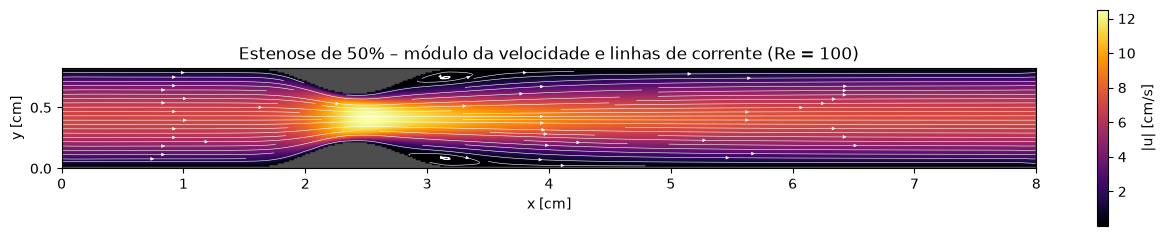

In [3]:
t0 = time.time()
r50 = simular(reducao=0.5, Re=100)
print(f"tempo: {time.time()-t0:.0f} s   (τ = {r50['tau']:.3f})")

def mostrar_campo(r, ax, titulo=""):
    e = escalas(r)
    u = np.ma.masked_array(r["ux"], r["sol"]); v = np.ma.masked_array(r["uy"], r["sol"])
    vel = np.hypot(u, v)*e["fu"]
    ext = [0, r["Nx"]*e["dx"], 0, r["Ny"]*e["dx"]]
    im = ax.imshow(vel.T, origin="lower", extent=ext, cmap="inferno")
    X, Y = np.meshgrid((np.arange(r["Nx"])+0.5)*e["dx"], (np.arange(r["Ny"])+0.5)*e["dx"])
    ax.streamplot(X, Y, u.T, v.T, color="w", density=[3, 0.8], linewidth=0.4, arrowsize=0.5)
    ax.set(xlabel="x [cm]", ylabel="y [cm]", title=titulo); ax.set_facecolor("0.3")
    plt.colorbar(im, ax=ax, label="|u| [cm/s]", shrink=0.8)

fig, ax = plt.subplots(figsize=(13, 3))
mostrar_campo(r50, ax, "Estenose de 50% – módulo da velocidade e linhas de corrente (Re = 100)")
plt.tight_layout(); plt.show()

Note o **jato** que se forma na garganta e as **zonas de recirculação** (vórtices) logo após a estenose, junto às paredes. Abaixo, a vorticidade $\omega_z = \partial v/\partial x - \partial u/\partial y$ destaca as camadas de cisalhamento.

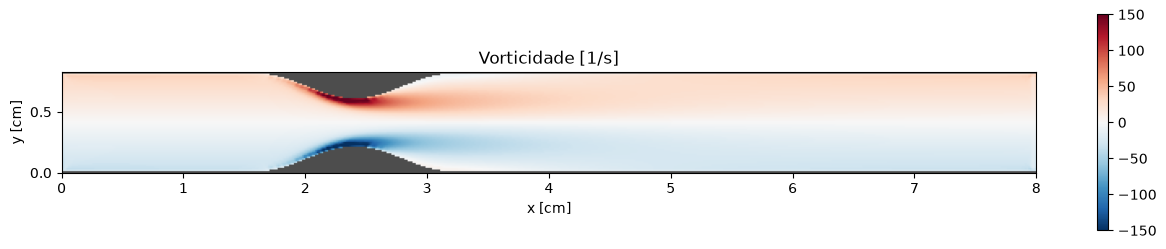

In [4]:
def vorticidade(r):
    e = escalas(r)
    w = (np.gradient(r["uy"], axis=0) - np.gradient(r["ux"], axis=1))*e["fu"]/e["dx"]
    return np.ma.masked_array(w, r["sol"])

fig, ax = plt.subplots(figsize=(13, 3))
e = escalas(r50)
im = ax.imshow(vorticidade(r50).T, origin="lower", cmap="RdBu_r", vmin=-150, vmax=150,
               extent=[0, r50["Nx"]*e["dx"], 0, r50["Ny"]*e["dx"]])
ax.set(xlabel="x [cm]", ylabel="y [cm]", title="Vorticidade [1/s]"); ax.set_facecolor("0.3")
plt.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()

## 4. Tensão de cisalhamento na parede (WSS)
Calculamos $\tau_w = \mu\,\partial u/\partial y$ na parede inferior e normalizamos pelo valor de Poiseuille no trecho reto, $\tau_0 = 6\mu U_{med}/H$.

* **WSS alto** na garganta: risco de dano endotelial e ativação plaquetária.
* **WSS negativo/baixo** na recirculação: região associada ao **crescimento da placa** aterosclerótica.

A curva cinza mostra o valor bruto: como a parede curva é representada por uma "escada" de células, o WSS oscila. Isso é uma limitação conhecida do *bounce-back* simples; métodos com contorno curvo (p. ex. Bouzidi) ou malhas ajustadas ao corpo, como no SimVascular, resolvem esse problema.

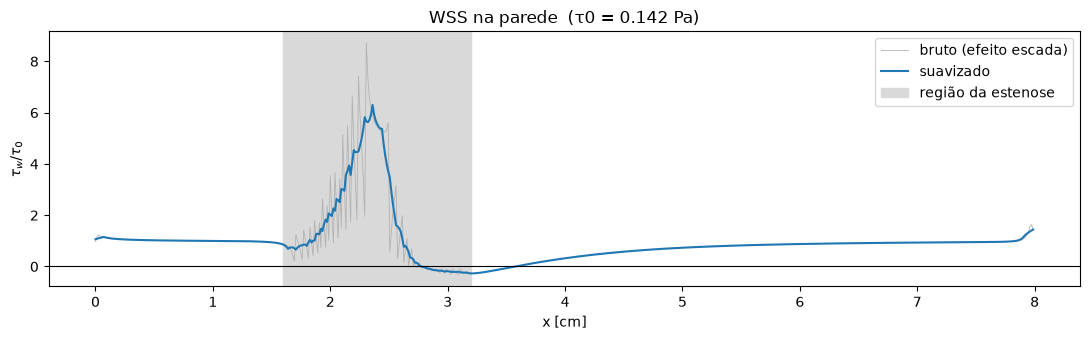

WSS máximo = 6.3 τ0;  recirculação ≈ 1.00 H


In [5]:
def wss_parede(r, suavizar=9):
    """τw/τ0 ao longo da parede inferior.
    du/dy é obtido por ajuste quadrático nas 3 primeiras células de fluido; a parede de bounce-back
    fica a meio caminho entre a célula sólida e a de fluido. Como a parede curva vira uma 'escada'
    de células, aplicamos uma média móvel de `suavizar` células."""
    sol, ux, H = r["sol"], r["ux"], r["H"]
    tw = np.zeros(r["Nx"])
    for x in range(r["Nx"]):
        j = np.argmax(~sol[x, :r["Ny"]//2])
        d = np.arange(j, j + 3) - (j - 0.5)
        tw[x] = np.linalg.lstsq(np.c_[d, d**2], ux[x, j:j+3], rcond=None)[0][0]
    if suavizar > 1:
        k = np.ones(suavizar)/suavizar
        tw = np.convolve(np.pad(tw, suavizar//2, mode="edge"), k, "valid")
    return tw/(6*r["u_med"]/H)

def recirculacao(r):
    """Comprimento da zona de recirculação a jusante da garganta, em diâmetros."""
    tw = wss_parede(r); H = r["H"]; xg = 3*H
    neg = np.where(tw[xg:] < 0)[0]
    return 0.0 if len(neg) == 0 else (neg.max() - neg.min() + 1)/H

e = escalas(r50); x = np.arange(r50["Nx"])*e["dx"]
tau0_Pa = 6*MU_FIS*e["U"]/H_FIS/10          # dyn/cm² → Pa
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(x, wss_parede(r50, suavizar=1), c="0.7", lw=0.6, label="bruto (efeito escada)")
ax.plot(x, wss_parede(r50), c="C0", label="suavizado"); ax.axhline(0, c="k", lw=0.8)
ax.axvspan(2*H_FIS, 4*H_FIS, color="0.85", label="região da estenose")
ax.set(xlabel="x [cm]", ylabel=r"$\tau_w/\tau_0$", title=f"WSS na parede  (τ0 = {tau0_Pa:.3f} Pa)")
ax.legend(); plt.tight_layout(); plt.show()
print(f"WSS máximo = {wss_parede(r50).max():.1f} τ0;  recirculação ≈ {recirculacao(r50):.2f} H")

## 5. Comparando graus de estenose
Agora repetimos para 30%, 50% e 65% de obstrução do diâmetro, medindo a queda de pressão **adicional** causada pela lesão (descontada a perda de Poiseuille do canal reto), o pico de WSS e o comprimento de recirculação. Leva ~3 minutos.

30% concluído em 28 s


65% concluído em 26 s

 obstrução  ΔP_est [mmHg]  WSS máx/τ0  recirc. [H]
       30%         0.0032         3.1         0.00


       50%         0.0183         6.3         1.00
       65%         0.0572        11.7         2.37


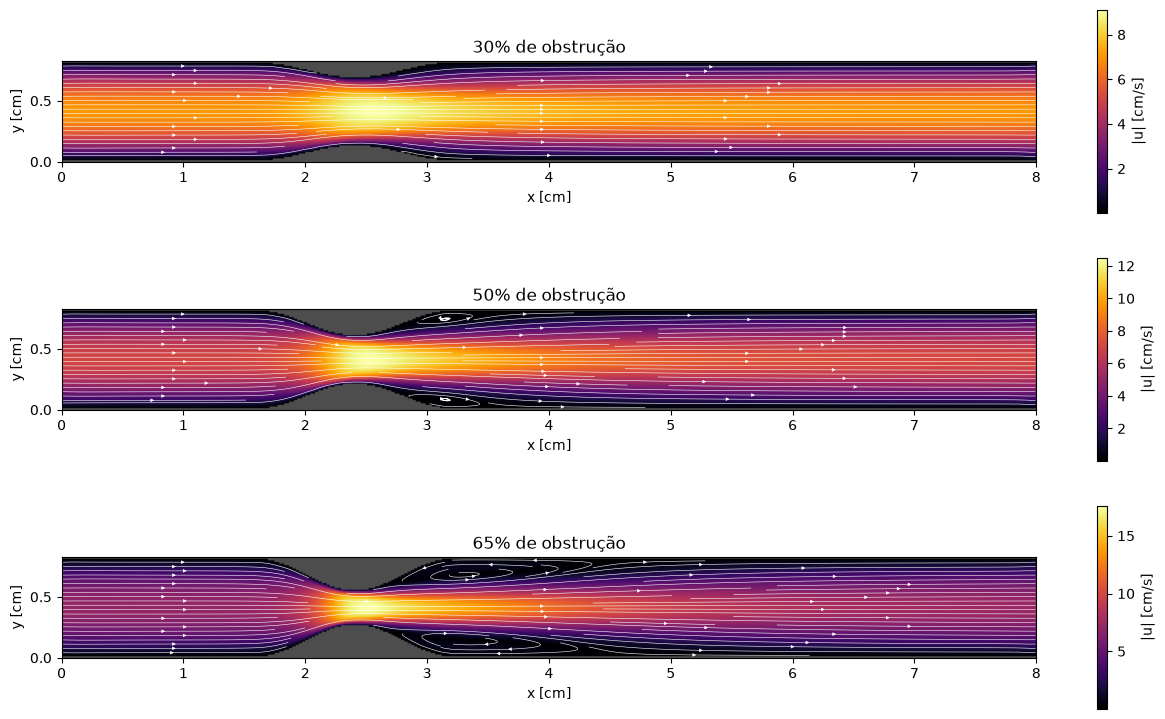

In [6]:
graus = [0.3, 0.5, 0.65]
resultados = {0.5: r50}
for g_ in graus:
    if g_ not in resultados:
        t0 = time.time(); resultados[g_] = simular(reducao=g_, Re=100)
        print(f"{g_*100:.0f}% concluído em {time.time()-t0:.0f} s")

fig, axs = plt.subplots(len(graus), 1, figsize=(13, 2.6*len(graus)))
print(f"\n{'obstrução':>10s} {'ΔP_est [mmHg]':>14s} {'WSS máx/τ0':>11s} {'recirc. [H]':>12s}")
for ax, g_ in zip(axs, graus):
    r = resultados[g_]; e = escalas(r); H = r["H"]
    mostrar_campo(r, ax, f"{g_*100:.0f}% de obstrução")
    dP_total = (r["rho"][H, 1:-1].mean() - r["rho"][7*H, 1:-1].mean())/3
    dP_pois = 12*r["nu"]*r["u_med"]/H**2*(6*H)        # queda de Poiseuille (canal reto) no mesmo trecho
    dP = (dP_total - dP_pois)*e["fp"]                   # queda extra causada pela estenose
    print(f"{g_*100:9.0f}% {dP:14.4f} {wss_parede(r).max():11.1f} {recirculacao(r):12.2f}")
plt.tight_layout(); plt.show()

## 6. Fluxo pulsátil (animação)
O sangue não escoa em regime permanente. Impomos na entrada $Q(t) = Q_0[1 + 0{,}6\sin(2\pi t/T)]$ e observamos os vórtices nascendo e sendo lavados a cada ciclo. Leva ~1–2 minutos.

In [7]:
T_passos = 8000
t0 = time.time()
rp = simular(reducao=0.5, Re=100, passos=3*T_passos, pulsatil=(0.6, T_passos), salvar_a_cada=200)
print(f"tempo: {time.time()-t0:.0f} s; período físico T = {T_passos*escalas(rp)['dt']:.2f} s")

e = escalas(rp); ext = [0, rp["Nx"]*e["dx"], 0, rp["Ny"]*e["dx"]]
fig, ax = plt.subplots(figsize=(12, 2.8))
it0, u0, v0 = rp["quadros"][0]
im = ax.imshow(np.ma.masked_array(np.hypot(u0, v0)*e["fu"], rp["sol"]).T, origin="lower",
               extent=ext, cmap="inferno", vmin=0, vmax=np.hypot(u0, v0).max()*e["fu"]*1.6)
ax.set_facecolor("0.3"); ax.set(xlabel="x [cm]", ylabel="y [cm]")
plt.colorbar(im, ax=ax, label="|u| [cm/s]", shrink=0.8)
def atualizar(k):
    it, u, v = rp["quadros"][k]
    im.set_data(np.ma.masked_array(np.hypot(u, v)*e["fu"], rp["sol"]).T)
    ax.set_title(f"t/T = {(it % T_passos)/T_passos:.2f}")
    return [im]
anim = animation.FuncAnimation(fig, atualizar, frames=len(rp["quadros"]), interval=100)
plt.close(fig); HTML(anim.to_jshtml())

tempo: 16 s; período físico T = 0.90 s


## 7. Exercícios sugeridos
1. **Reynolds:** rode a estenose de 50% com `Re=50` e `Re=200` (para Re = 200, use `Ny=82` e `passos=60000`). Como o comprimento de recirculação escala com Re?
2. **Comparação com o 0D:** use a queda de pressão da Seção 5 para estimar um coeficiente de estenose $S$ e compare com a fórmula de Young & Tsai do notebook anterior. Por que um modelo 2D (canal planar) não deve reproduzi-la exatamente?
3. **Convergência de malha:** repita a Seção 3 com `Ny=42` e `Ny=82` (mesmo Re). O pico de WSS converge?
4. **Geometria:** modifique a função `geometria` para criar uma estenose **assimétrica** (só na parede inferior). O que acontece com o jato?
5. **Womersley:** no caso pulsátil, varie `T_passos` e relacione com o número de Womersley $\alpha = (H/2)\sqrt{\omega/\nu}$.

### Respostas e Discussão dos Exercícios Sugeridos

#### 1. Escalonamento da Recirculação com o Reynolds:
- **Comportamento físico:** À medida que o número de Reynolds aumenta (de $Re = 50$ para $Re = 200$), a inércia do jato que passa pela garganta supera com mais força a difusão viscosa. Como consequência, o jato penetra mais profundamente a jusante antes de se alargar e restabelecer o contato com a parede. O **comprimento da zona de recirculação ($L_{\text{rec}}$)** escala de forma aproximadamente linear com o Reynolds ($L_{\text{rec}}/H \propto Re$) no regime laminar, aumentando consideravelmente a área de estagnação pós-estenótica.

#### 2. Comparação entre o Modelo 2D e o Modelo 0D (Young & Tsai):
- **Estimativa do coeficiente $S$:** No modelo 0D, a queda de pressão adicional por estenose é dada por $\Delta P_{\text{estenose}} = S \cdot Q^2$. Pelo modelo LBM 2D, medimos $\Delta P$ e a vazão integrada no canal planar.
- **Por que o modelo 2D não reproduz perfeitamente o 0D?**
  1. **Geometria:** O modelo 2D LBM representa um **canal plano entre placas infinitas** (escoamento de Poiseuille planar, onde a vazão por largura unitária varia com $H^3$), enquanto o modelo 0D de Young & Tsai foi derivado e calibrado experimentalmente para **tubos cilíndricos 3D** (onde $Q \propto R^4$).
  2. **Efeito de confinamento e vorticidade:** Em 2D, as linhas de vórtice são puramente ortogonais ao plano ($z$), não havendo estiramento tridimensional de vórtices (*vortex stretching*), o que altera a taxa de dissipação de energia turbilhonar na expansão pós-estenótica.

#### 3. WSS e Aterosclerose: Por que as placas crescem a jusante e não na garganta?
- **Na garganta:** Observamos um **pico acentuado de WSS** (mais de $6\times$ a $12\times$ o nível basal). O cisalhamento unidirecional elevado exerce um efeito mecânico protetor de 'varredura', impedindo a adesão de lipoproteínas de baixa densidade (LDL) e monócitos. Contudo, em estenoses severas, o WSS extremo pode causar desnudamento mecânico do endotélio, ruptura da capa fibrosa e trombose aguda.
- **A jusante (zona de recirculação):** A separação do jato engendra uma região com **WSS muito baixo, oscilatório ou até negativo** (fluxo retrógrado reverso). Esse microambiente hemodinâmico é altamente ateroprogênico: promove o aumento do tempo de residência das partículas aterogênicas junto à parede celular, ativa vias de transcrição inflamatórias (NF-κB) nas células endoteliais, aumenta a permeabilidade da monocamada endotelial e facilita a penetração subendotelial de macrófagos e colesterol. É exatamente nessa região distal de recirculação que as placas ateroscleróticas se expandem e se desestabilizam.
